In [1]:

# conda create -n clouds -c conda-forge python=3.11 numpy pandas h5py matplotlib scipy scikit-learn catboost cartopy plotly python-kaleido jupyterlab ipykernel -y
# conda activate clouds
# python -m ipykernel install --user --name clouds --display-name "Python (clouds)"


In [23]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from catboost import CatBoostClassifier
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.metrics import (average_precision_score, confusion_matrix,
                             log_loss, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, train_test_split

from matplotlib.lines import Line2D


SEED = 42

FILE = 'data/20170710_s2_manual_classification_data.h5'

savefig_path = 'figs/'

# explore the data 

In [24]:
# data structure

with h5py.File(FILE) as f:
    for name, item in f.items():
        print(f"{name:25s} shape={str(item.shape):15s} type={item.dtype}")

author                    shape=()              type=object
band                      shape=(13,)           type=|S2
bandwidth_nm              shape=(13,)           type=int16
central_wavelength_nm     shape=(13,)           type=int16
cite                      shape=()              type=object
class_ids                 shape=(6,)            type=int8
class_names               shape=(6,)            type=|S6
classes                   shape=(3028733,)      type=int8
continent                 shape=(3028733,)      type=|S32
dates                     shape=(3028733,)      type=|S16
granule_id                shape=(3028733,)      type=|S32
latitude                  shape=(3028733,)      type=float64
licence                   shape=()              type=object
longitude                 shape=(3028733,)      type=float64
product_id                shape=(3028733,)      type=|S85
spatial_sampling_m        shape=(13,)           type=int16
spectra                   shape=(3028733, 13)   type=float1

In [25]:
# what is actually inside 

def dec(a):
    """Convert byte strings from the file into normal text."""
    a = np.asarray(a)
    if a.dtype.kind == "S":
        return np.char.decode(a, "utf-8")
    if a.dtype.kind == "O":
        return np.array([x.decode() if isinstance(x, bytes) else x for x in a])
    return a

with h5py.File(FILE) as f:
    print(pd.DataFrame({
        "band": dec(f["band"][()]),
        "wavelength_nm": f["central_wavelength_nm"][()],
        "bandwidth_nm": f["bandwidth_nm"][()],
        "resolution_m": f["spatial_sampling_m"][()],
    }).to_string(index=False))

    print("\nClasses:", dict(zip(f["class_ids"][()].tolist(),
                                 dec(f["class_names"][()]).tolist())))

    per_pixel = ["classes", "product_id", "granule_id", "dates", "continent",
                 "latitude", "longitude", "sun_zenith_angle",
                 "sun_azimuth_angle", "viewing_zenith_angle"]
    print("\nFirst rows:")
    print(pd.DataFrame({k: dec(f[k][:3]) for k in per_pixel}).T.to_string())

    print("\nFirst spectrum:", f["spectra"][0])

    for k in ["author", "cite", "licence"]:
        print(f"\n{k}:", dec(f[k][()]))

band  wavelength_nm  bandwidth_nm  resolution_m
   1            443            20            60
   2            490            65            10
   3            560            35            10
   4            665            30            10
   5            705            15            20
   6            740            15            20
   7            783            20            20
   8            842           115            10
  8a            865            20            20
   9            945            20            60
  10           1380            30            60
  11           1610            90            20
  12           2190           180            20

Classes: {30: 'Shadow', 50: 'Cloud', 10: 'Clear', 20: 'Water', 40: 'Cirrus', 60: 'Snow'}

First rows:
                                                                                                        0                                                                                    1                                   

In [26]:
with h5py.File(FILE) as f:
    X = f["spectra"][()].astype(np.float64)
    bands = np.array([f"B{b.upper()}".replace("A", "a") for b in dec(f["band"][()]).astype(str)])
    wavelengths = f["central_wavelength_nm"][()]
    names = dict(zip(f["class_ids"][()].tolist(), dec(f["class_names"][()]).tolist()))
    df = pd.DataFrame({
        "cls": pd.Series(f["classes"][()]).map(names),
        "product_id": dec(f["product_id"][()]),
        "granule_id": dec(f["granule_id"][()]),
        "latitude": f["latitude"][()],
        "longitude": f["longitude"][()],
        "sun_zenith": f["sun_zenith_angle"][()],
    })

# Merge linked products and granules into scene groups
p, _ = pd.factorize(df["product_id"])
g, _ = pd.factorize(df["granule_id"])
g = g + p.max() + 1
n = g.max() + 1
graph = coo_matrix((np.ones(len(p)), (p, g)), shape=(n, n))
_, labels = connected_components(graph, directed=False)
df["group"] = labels[p]

CLASSES = ["Cloud", "Snow", "Cirrus", "Clear", "Water", "Shadow"]
COLORS = dict(zip(CLASSES, ["tab:orange", "tab:cyan", "tab:blue", "tab:green", "navy", "tab:gray"]))
print(df["cls"].value_counts(), "\nScene groups:", df["group"].nunique(), "\nBands:", bands)

cls
Clear     1040411
Cirrus     499372
Cloud      486430
Water      447811
Snow       417414
Shadow     137295
Name: count, dtype: int64 
Scene groups: 39 
Bands: ['B1' 'B2' 'B3' 'B4' 'B5' 'B6' 'B7' 'B8' 'B8a' 'B9' 'B10' 'B11' 'B12']


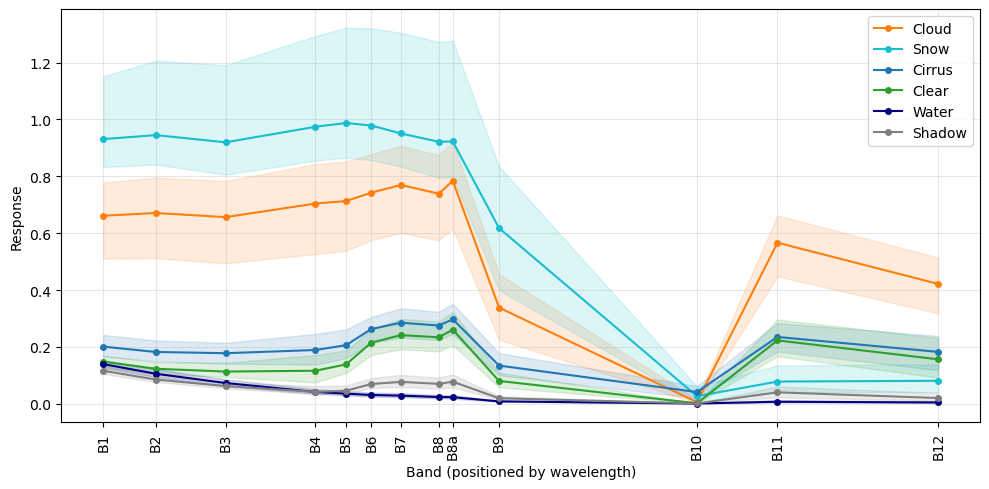

In [27]:
fig, ax = plt.subplots(figsize=(10, 5))
order = np.argsort(wavelengths)

for c in CLASSES:
    S = X[df["cls"] == c][:, order]
    q25, med, q75 = np.percentile(S, [25, 50, 75], axis=0)
    ax.plot(wavelengths[order], med, "-o", ms=4, color=COLORS[c], label=c)
    ax.fill_between(wavelengths[order], q25, q75, color=COLORS[c], alpha=0.15)

ax.set_xscale("log")
ax.set_xticks(wavelengths[order], bands[order], rotation=90)
ax.minorticks_off()
ax.set_xlabel("Band (positioned by wavelength)")
ax.set_ylabel("Response")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()


fig.savefig(savefig_path+'spectral_signatures.png', dpi=300, bbox_inches = 'tight')


# plt.show()

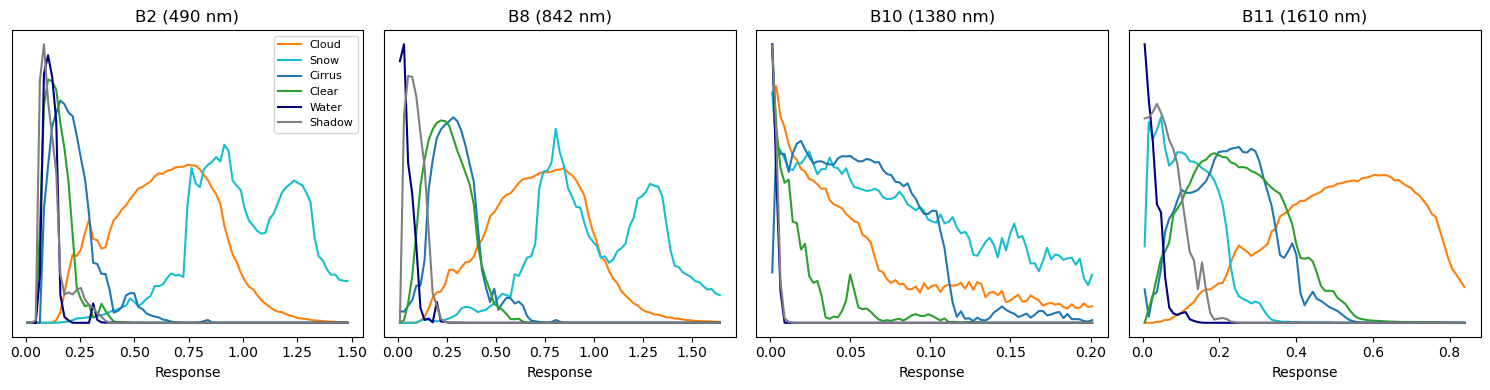

In [28]:
key_bands = ["B2", "B8", "B10", "B11"]
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

for ax, b in zip(axes, key_bands):
    j = list(bands).index(b)
    hi = np.percentile(X[:, j], 99.5)
    edges = np.linspace(0, hi, 80)
    centers = (edges[:-1] + edges[1:]) / 2
    for c in CLASSES:
        h, _ = np.histogram(X[df["cls"] == c, j], bins=edges, density=True)
        ax.plot(centers, h, color=COLORS[c], label=c, lw=1.5)
    ax.set_title(f"{b} ({wavelengths[j]} nm)")
    ax.set_xlabel("Response")
    ax.set_yscale("symlog", linthresh=1)
    ax.set_yticks([])
    ax.minorticks_off()

axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(savefig_path+'key_band_distributions.png', dpi=300, bbox_inches = 'tight')



/Users/varyabazilova/miniconda3/envs/alluvialfans/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/varyabazilova/miniconda3/envs/alluvialfans/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/varyabazilova/miniconda3/envs/alluvialfans/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/varyabazilova/miniconda3/envs/alluvialfans/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/varyabazilova/minicon

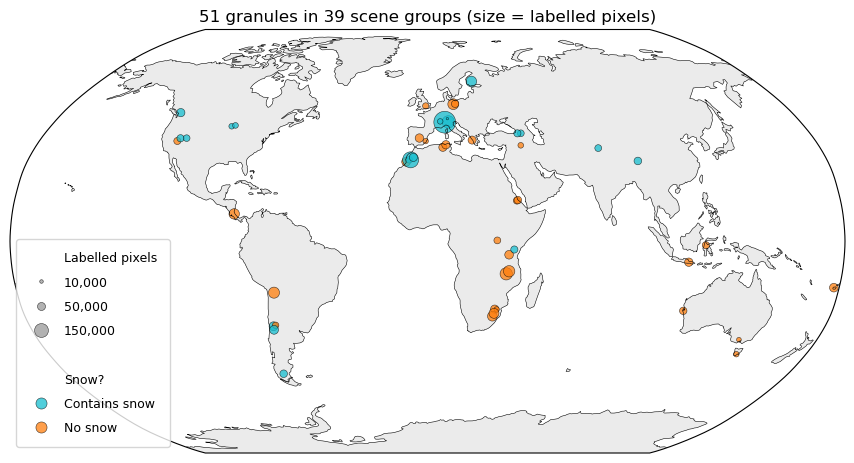

In [39]:
pts = (df.groupby(["group", "granule_id"])
         .agg(lon=("longitude", "median"),
              lat=("latitude", "median"),
              pixels=("cls", "size"))
         .reset_index())

has_snow = df[df["cls"] == "Snow"].groupby("granule_id").size()
pts["has_snow"] = pts["granule_id"].isin(has_snow.index)

color=np.where(pts["has_snow"], "tab:cyan", "tab:orange")

fig = plt.figure(figsize=(11, 5.5))
ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()
ax.add_feature(cfeature.LAND, facecolor="0.92")
ax.add_feature(cfeature.OCEAN, facecolor="white")
ax.add_feature(cfeature.COASTLINE, linewidth=0.4)

ax.scatter(pts.lon, pts.lat, s=pts.pixels / 1500,
           color=color, alpha=0.75,
           edgecolor="k", linewidth=0.4,
           transform=ccrs.PlateCarree())


# for n in [10000, 50000, 150000]:
    # ax.scatter([], [], s=n / 1500, color="tab:orange", alpha=0.75,
               # edgecolor="k", linewidth=0.4, label=f"{n:,}")
# ax.legend(title="Labelled pixels", loc="lower left", frameon=True,
          # labelspacing=1.2, borderpad=1, fontsize=9, title_fontsize=9)

def dot(color, size, label):
    return Line2D([], [], marker="o", linestyle="", color=color, alpha=0.75,
                  markeredgecolor="k", markeredgewidth=0.4,
                  markersize=size, label=label)

heading = lambda text: Line2D([], [], linestyle="", label=text)

handles = [
    heading("Labelled pixels"),
    *[dot("0.6", np.sqrt(n / 1500), f"{n:,}") for n in [10000, 50000, 150000]],
    heading(" "),
    heading("Snow?"),
    dot("tab:cyan", 8, "Contains snow"),
    dot("tab:orange", 8, "No snow"),
]

ax.legend(handles=handles, loc="lower left", frameon=True,
          labelspacing=0.9, borderpad=1, fontsize=9)


ax.set_title(f"{len(pts)} granules in {pts.group.nunique()} scene groups (size = labelled pixels)")


fig.savefig(savefig_path+'scene_map.png', dpi=300, bbox_inches="tight")


         pixels  scenes  share_%
cls                             
Cloud    486430      29     16.1
Snow     417414      17     13.8
Cirrus   499372      14     16.5
Clear   1040411      38     34.4
Water    447811      29     14.8
Shadow   137295      22      4.5


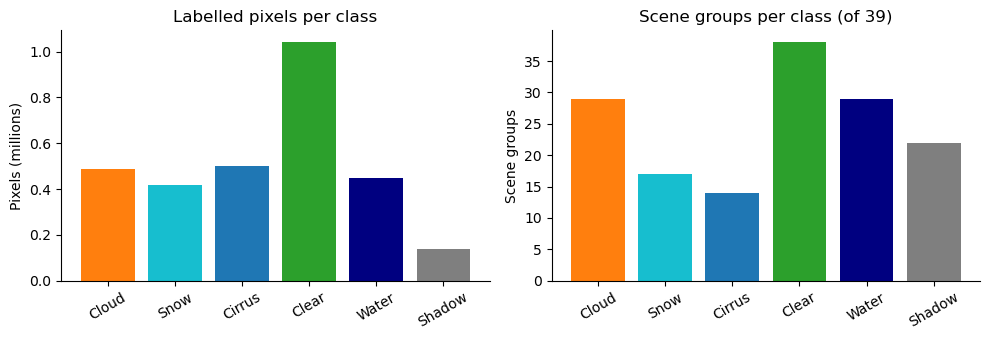

In [42]:
summary = df.groupby("cls").agg(pixels=("group", "size"),
                                scenes=("group", "nunique")).reindex(CLASSES)
summary["share_%"] = (100 * summary.pixels / summary.pixels.sum()).round(1)
print(summary.to_string())

colors = [COLORS[c] for c in CLASSES]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].bar(CLASSES, summary.pixels / 1e6, color=colors)
axes[0].set_ylabel("Pixels (millions)")
axes[0].set_title("Labelled pixels per class")

axes[1].bar(CLASSES, summary.scenes, color=colors)
axes[1].set_ylabel("Scene groups")
axes[1].set_title(f"Scene groups per class (of {df.group.nunique()})")

for ax in axes:
    ax.tick_params(axis="x", rotation=30)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()


fig.savefig(savefig_path+"class_balance.png", dpi=300, bbox_inches = 'tight')


# data splitting: train test validation

In [44]:
TARGET_NAMES = ["Rest", "Cloud", "Snow", "Water"]
cls = df["cls"].to_numpy()
groups = df["group"].to_numpy()

y = np.select([cls == "Cloud", cls == "Snow", cls == "Water"], [1, 2, 3], default=0)
print(pd.Series(y).map(dict(enumerate(TARGET_NAMES))).value_counts())

Rest     1677078
Cloud     486430
Water     447811
Snow      417414
Name: count, dtype: int64


In [48]:
CAP = None   # max pixels per scene group in train and validation; None = use all

# 1. Set aside the holdout, chosen from class coverage only, never model scores
holdout_groups = None
for seed in range(SEED, SEED + 100):
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    _, candidate = next(sgkf.split(X, y, groups))
    gs = groups[candidate]
    enough = all(len(np.unique(gs[cls[candidate] == c])) >= 3
                 for c in ["Cloud", "Snow", "Water", "Cirrus"])
    if enough and 7 <= len(np.unique(gs)) <= 9:
        holdout_groups = np.unique(gs)
        print("Holdout chosen with seed", seed)
        break
assert holdout_groups is not None, "No holdout met the coverage rule"

is_holdout = np.isin(groups, holdout_groups)
holdout_idx = np.flatnonzero(is_holdout)
dev_idx = np.flatnonzero(~is_holdout)
pd.Series(holdout_groups).to_csv("holdout_groups.csv", index=False)

def cap_per_group(idx, seed=SEED):
    if CAP is None:
        return idx
    rng = np.random.default_rng(seed)
    kept = []
    for grp in np.unique(groups[idx]):
        members = idx[groups[idx] == grp]
        if len(members) > CAP:
            members = rng.choice(members, CAP, replace=False)
        kept.append(members)
    return np.concatenate(kept)

# 2. Cross-validation uses development scenes only
splits = []
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
for a, b in outer.split(X[dev_idx], y[dev_idx], groups[dev_idx]):
    dev, te = dev_idx[a], dev_idx[b]
    inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    i, j = next(inner.split(dev, y[dev], groups[dev]))
    tr, va = dev[i], dev[j]

    assert not set(groups[tr]) & set(groups[va])
    assert not set(groups[tr]) & set(groups[te])
    assert not set(groups[va]) & set(groups[te])
    assert not set(groups[np.r_[tr, va, te]]) & set(holdout_groups)

    splits.append({"train": cap_per_group(tr), "val": cap_per_group(va), "test": te})

print(f"Holdout: {len(holdout_groups)} groups, {len(holdout_idx):,} pixels")
print(f"Development: {len(np.unique(groups[dev_idx]))} groups, {len(dev_idx):,} pixels")
print("Holdout pixels by class:")
print(pd.Series(cls[holdout_idx]).value_counts().to_string())
print("\nHoldout scene groups by class:")
print(pd.Series(groups[holdout_idx]).groupby(cls[holdout_idx]).nunique().to_string())
print("\nAll leakage checks passed")

Holdout chosen with seed 42
Holdout: 9 groups, 575,439 pixels
Development: 30 groups, 2,453,294 pixels
Holdout pixels by class:
Cirrus    146493
Clear     140598
Cloud      92021
Water      91638
Snow       74305
Shadow     30384

Holdout scene groups by class:
Cirrus    4
Clear     8
Cloud     7
Shadow    5
Snow      5
Water     7

All leakage checks passed


In [49]:
rows = []
for k, s in enumerate(splits):
    for part, idx in s.items():
        counts = np.bincount(y[idx], minlength=len(TARGET_NAMES))
        row = {"fold": k, "part": part,
               "groups": len(np.unique(groups[idx])), "pixels": len(idx)}
        row.update(dict(zip(TARGET_NAMES, counts)))
        for i, name in enumerate(TARGET_NAMES[1:], start=1):
            row[f"{name}_groups"] = len(np.unique(groups[idx][y[idx] == i]))
        rows.append(row)

        
print(pd.DataFrame(rows).to_string(index=False))

 fold  part  groups  pixels   Rest  Cloud   Snow  Water  Cloud_groups  Snow_groups  Water_groups
    0 train      23 1542934 829736 290228 203863 219107            15            8            16
    0   val       3  423979 256204  35540  70644  61591             3            1             3
    0  test       4  486381 273663  68641  68602  75475             4            3             3
    1 train      25 1562114 818985 302658 218331 222140            18            9            17
    1   val       2  408431 254627  35101  54134  64569             1            2             2
    1  test       3  482749 285991  56650  70644  69464             3            1             3
    2 train      22 1567198 863920 267074 221893 214311            18            8            16
    2   val       2  408431 254627  35101  54134  64569             1            2             2
    2  test       6  477665 241056  92234  67082  77293             3            2             4
    3 train      16 1554685 87